In [1]:
#importing library
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import data_utils as du

In [3]:
#Importing the dataset
reg_path= "../../data/Regression_datasets/telecom.csv"
reg_data= pd.read_csv(reg_path)
print(reg_data.head())

   data_usage  call_duration  plan_type  bill_amount
0   10.049547     608.458730          3   695.356883
1   21.902884     357.879865          3   665.274319
2    7.956519     384.375842          3   550.847293
3    4.618794     108.280089          2   287.242847
4    1.454391     295.619571          3   477.080111


In [4]:
#data exploration
du.data_exploration(reg_data)

DATA EXPLORATION
Shape of dataset: 10000 rows, 4 columns

Columns: ['data_usage', 'call_duration', 'plan_type', 'bill_amount']

Data Types:
 data_usage       float64
call_duration    float64
plan_type          int64
bill_amount      float64
dtype: object

Missing Values:
 data_usage       0
call_duration    0
plan_type        0
bill_amount      0
dtype: int64

Statistical Summary:
          data_usage  call_duration     plan_type   bill_amount
count  10000.000000   10000.000000  10000.000000  10000.000000
mean       9.893560     301.011658      1.987500    448.032056
std        7.037203     100.573071      0.814254    120.093816
min        0.088321     -82.589107      1.000000    135.429348
25%        4.789937     232.611190      1.000000    361.489206
50%        8.281673     302.132561      2.000000    444.797645
75%       13.188322     368.948168      3.000000    527.516256
max       63.329828     665.194253      3.000000   1022.831405


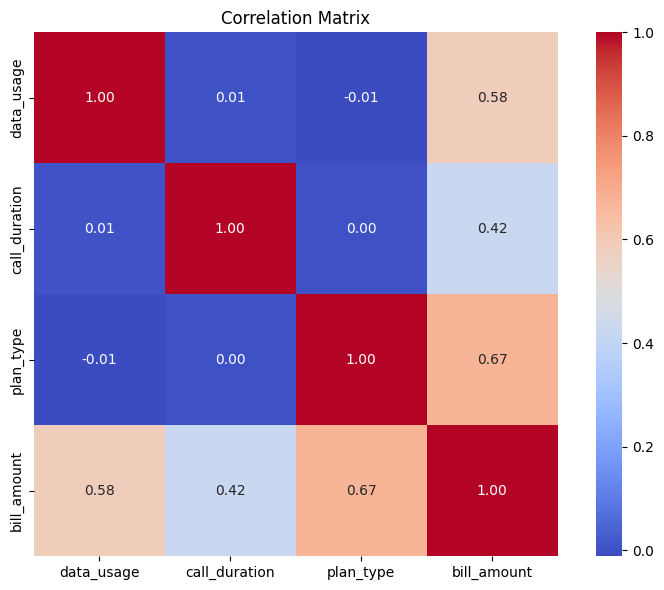

In [5]:
#data visualization
corr = du.get_correlation_matrix(reg_data)
du.plot_correlation_matrix(corr)

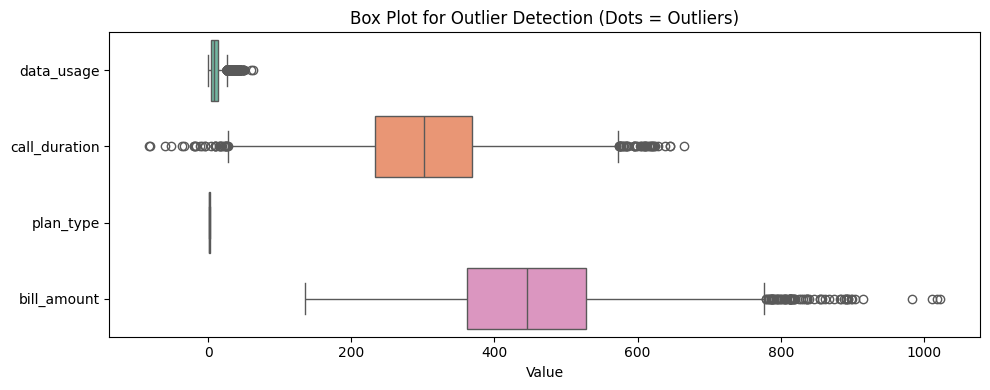

In [6]:
#check for outliers
cols = reg_data.columns
du.plot_boxplots(reg_data, cols)

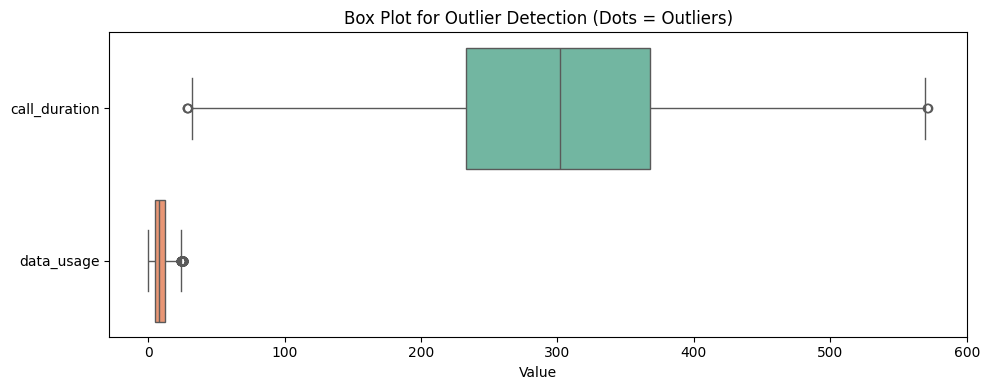

In [7]:
outlier_cols = ['call_duration','data_usage']
df_clean = du.remove_outliers_iqr(reg_data, outlier_cols)
du.plot_boxplots(df_clean, outlier_cols)

In [9]:
#linear regression 
X = df_clean.drop('bill_amount', axis=1)
y = df_clean['bill_amount']

In [10]:
model, mse, r2, y_test, y_pred =    du.linear_regression_model(X, y)

Mean Squared Error: 373.2732
R-squared: 0.9698


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [11]:
du.cross_validation(model, X, y, cv=5)

5-Fold Cross-Validation (r2): [0.97009635 0.96793358 0.97069014 0.9677621  0.96874351]
Average CV score: 0.9690 (± 0.0012)


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: i

array([0.97009635, 0.96793358, 0.97069014, 0.9677621 , 0.96874351])

97% prediction accuracy can able to attain using this data


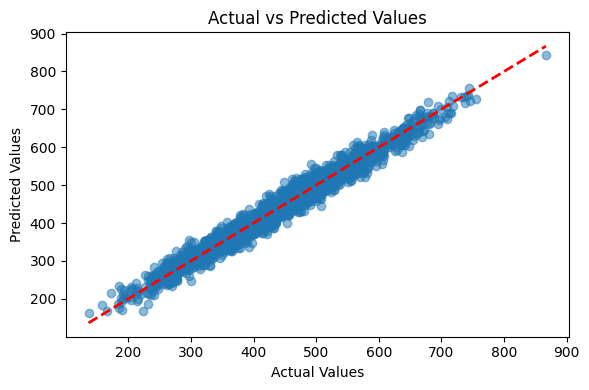

In [12]:
du.plot_actual_vs_predicted(y_test, y_pred)